In [ ]:
from langchain_groq import ChatGroq
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import Chroma
from dotenv import load_dotenv
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.documents import Document
from pydantic import BaseModel , Field
from typing import TypedDict, Annotated , Literal
from langgraph.graph import START , END , StateGraph
from langchain_google_genai import ChatGoogleGenerativeAI
import re
from langchain_core.prompts import ChatPromptTemplate
from PIL import Image
import io

C:\Users\Hunain Xps\AppData\Local\Temp\ipykernel_20980\854361169.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [2]:
load_dotenv()

True

In [3]:
embeedings = HuggingFaceEmbeddings(model_name= "sentence-transformers/all-MiniLM-L6-v2")

HTTP Error 429 thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/adapter_config.json
Retrying in 1s [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/adapter_config.json
Retrying in 2s [Retry 2/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/adapter_config.json
Retrying in 4s [Retry 3/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/adapter_config.json
Retrying in 8s [Retry 4/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/adapter_config.json
Retrying in 8s [Retry 5/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/adapter_config.json


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

HTTP Error 429 thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json
Retrying in 1s [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json
Retrying in 2s [Retry 2/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json
Retrying in 4s [Retry 3/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json
Retrying in 8s [Retry 4/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json
Retrying in 8s [Retry 5/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json
HTTP Error 429

In [4]:
vector_store = Chroma(
    persist_directory="./chroma_db",
    embedding_function=embeedings
)
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})

C:\Users\Hunain Xps\AppData\Local\Temp\ipykernel_20980\1853629439.py:1: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the `langchain-chroma package and should be used instead. To use it run `pip install -U `langchain-chroma` and import as `from `langchain_chroma import Chroma``.
  vector_store = Chroma(


In [5]:
upper_threshold = 0.7
lower_threshold = 0.3

In [6]:
strip_model = ChatGoogleGenerativeAI(model= "gemini-3.1-flash-lite")
model  = ChatGroq(model= "llama-3.3-70b-versatile")

In [7]:
class State(TypedDict):
    question : str 
    docs : list[Document]
    
    good_docs : list[Document]
    verdict : str
    reason  : str
    
    
    strips : list[str]
    kept_strips : list[str]
    refined_context : str
    
    answer : str
    

In [ ]:
def retrieve(state : State)->State:
    query =state['question']
    retrieved_docs = retriever.invoke(query)
    return {'docs' : retrieved_docs}


In [9]:
class evalutor_model(BaseModel):
    score : float
    reason : str
    
doc_eval_prompt = ChatPromptTemplate.from_messages(
    [
       (
            "system",
            "You are a strict retrieval evaluator for RAG.\n"
            "You will be given ONE retrieved chunk and a question.\n"
            "Return a relevance score in [0.0, 1.0].\n"
            "- 1.0: chunk alone is sufficient to answer fully/mostly\n"
            "- 0.0: chunk is irrelevant\n"
            "Be conservative with high scores.\n"
            "Also return a short reason.\n"
            "Output JSON only."
        ),
      ("human","Question: {question}\n\nChunk:\n{chunk}")
    ]
)

eval_chain = doc_eval_prompt | strip_model.with_structured_output(evalutor_model)

In [10]:
def eval_each_doc_node(state :State)-> State:
    q = state['question']
    
    scores : list[float] = []
    reasons : list[str] = []
    good : list[Document] = []
    
    for d in state['docs']:
        out = eval_chain.invoke({"question" : q , "chunk" : d.page_content})
        scores.append(out.score)
        reasons.append(out.reason)
        if out.score > lower_threshold:
            good.append(d)
    
    if any(s > upper_threshold for s in scores):
        return {
            "good_docs": good,
            "verdict": "CORRECT",
            "reason": f"At least one retrieved chunk scored > {upper_threshold}.",
        }

    if len(scores) > 0 and all(s < lower_threshold for s in scores):
        why = "No chunk was sufficient."
        return {
            "good_docs": [],
            "verdict": "INCORRECT",
            "reason": f"All retrieved chunks scored < {lower_threshold}. {why}",
        }

    
    why = "Mixed relevance signals."
    return {
        "good_docs": good,
        "verdict": "AMBIGUOUS",
        "reason": f"No chunk scored > {upper_threshold}, but not all were < {lower_threshold}. {why}",
    }

In [11]:
def decompose_to_sentences(text: str) -> list[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]

In [12]:
class keepordrop(BaseModel):
    keep :bool

In [13]:
filter_prompt = ChatPromptTemplate.from_messages(
    [
         ("system",
            "You are a strict relevance filter.\n"
            "Return keep=true only if the sentence directly helps answer the question.\n"
            "Use ONLY the sentence. Output JSON only."),
         
         ("human", "Question: {question}\n\nSentence:\n{sentence}")
    ]
)

filter_chain = filter_prompt | strip_model.with_structured_output(keepordrop)


In [14]:
def refine(state : State) -> State:
    q = state['question']
    context = "\n\n".join(d.page_content for d in state['good_docs']).strip()
    strips = decompose_to_sentences(context)
    
    kept  : list[str] = []
    for s in strips:
        if filter_chain.invoke({"question" : q , "sentence" : s }).keep:
            kept.append(s)
        
    refined_context ="\n".join(kept).strip()
    return {
        
        "strips":strips , 
        "kept_strips" : kept ,
        "refined_context" : refined_context
        
            }
    
    

In [15]:
answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a helpful ML tutor. Answer ONLY using the provided refined bullets.\n"
            "If the bullets are empty or insufficient, say: 'I don't know based on the provided books.'",
        ),
        ("human", "Question: {question}\n\nRefined context:\n{refined_context}"),
    ]
)

In [16]:
def generate(state : State)-> State:
    res = (answer_prompt | model).invoke({"question" : state['question'] , "refined_context" : state['refined_context']}).content
    return {"answer" : res}
    

In [17]:
def fail_node(state: State) -> State:
    return {"answer": f"FAIL: {state['reason']}"}

def ambiguous_node(state: State) -> State:
    return {"answer": f"Ambiguous: {state['reason']}"}

    

In [18]:
def route_after_eval(state: State) -> str:
    if state["verdict"] == "CORRECT":
        return "refine"
    elif state["verdict"] == "INCORRECT":
        return "web_search"
    else:
        return "ambiguous"

In [19]:
graph = StateGraph(State)

graph.add_node("retrieve" , retrieve)
graph.add_node("refine" , refine)
graph.add_node("generate" , generate)
graph.add_node("eval_each_doc" , eval_each_doc_node)
graph.add_node('fail' , fail_node)
graph.add_node("ambiguous" , ambiguous_node)

In [20]:
graph.add_edge(START , "retrieve")
graph.add_edge("retrieve" , "eval_each_doc")
graph.add_conditional_edges("eval_each_doc" , route_after_eval , {"refine": "refine", "web_search": "fail", "ambiguous": "ambiguous"})
graph.add_edge("refine" ,"generate" )
graph.add_edge("generate" , END)
graph.add_edge("fail" , END)
graph.add_edge("ambiguous" , END)


workflow = graph.compile()

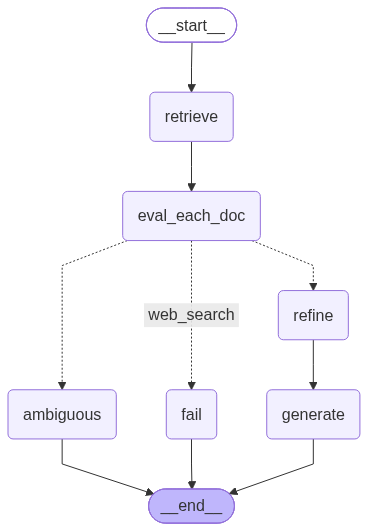

In [21]:
workflow

In [ ]:
res = workflow.invoke(
    {
        "question": "What are attention mechanisms and why are they important in current models?"
        
    }
)

print("VERDICT:", res["verdict"])
print("REASON:", res["reason"])
print("OUTPUT:", res["answer"])


VERDICT: INCORRECT
REASON: All retrieved chunks scored < 0.3. No chunk was sufficient.

OUTPUT:
 FAIL: All retrieved chunks scored < 0.3. No chunk was sufficient.
